In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
from hidro_tools import modelo_tanques

In [9]:
# Lectura de datos
df = pd.read_csv(
    '0022057010-Q_MEDIA_D.csv',
    index_col=0,
    parse_dates=True,
    usecols=[0,1]
)
df = df.resample('D').mean()

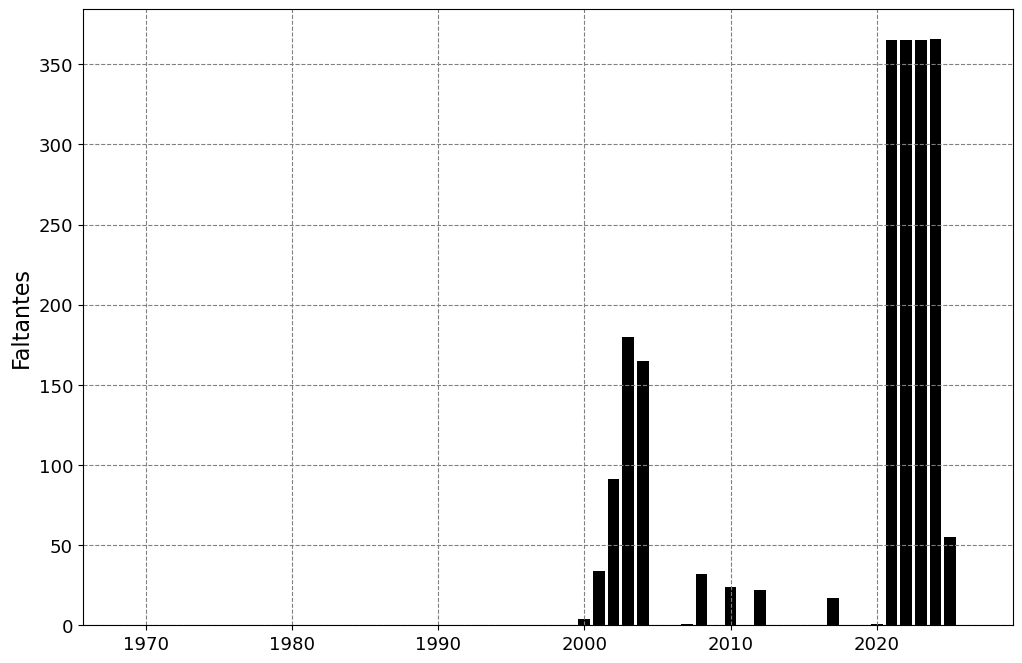

In [15]:
faltantes = df.isna().groupby(df.index.year).sum()
# ploteo de los faltantes
x = faltantes.index
y = faltantes.iloc[:,0]
plt.figure(figsize=(12,8))
plt.bar(x=x,height=y,color='black')
plt.ylabel('Faltantes',fontsize=16)
plt.yticks(size=13)
plt.xticks(size=13)
plt.grid(linestyle='--',color='grey')

## Delimitacion cuenca Piedra de Cobre

In [24]:
gdf = gpd.read_file('CNE_actualizado')
mask = gdf['Codigo'] == '22057010'
est_piedra_cobre = gdf[mask]
lon, lat = est_piedra_cobre['X'].values,est_piedra_cobre['Y'].values